# Cython

Чтобы использовать Cython в Jupyter тетрадке, нужно загрузить его как расширение.

In [1]:
%load_ext cython

### Привет, Cython!

Ну [привет](https://cython.readthedocs.io/en/latest/src/quickstart/build.html)...

In [2]:
%%cython --annotate

# -a = --annotate

def say_hello_to(name: str) -> None:
    print(f"Hello {name}!")

say_hello_to("Cython")

Hello Cython!


Видно, что Cython смог обработать чистый Python код.

Сравню разные имплементации задачи "сложения всех целых чисел с 1 по `n`".

In [3]:
# Pure Python function

def sum_py(n: int) -> int:
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    s = 0
    for i in range(1, n + 1):
        s += i
    return s

In [4]:
%%cython

# Pure Python passed through Cython

# practically copy-pasted
def sum_py_via_cython(n: int) -> int:
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    s = 0
    for i in range(1, n + 1):
        s += i
    return s

In [5]:
%%cython

cimport cython  # Cython import statement

# def -> this Cython function is accessible in Python
# `int n` - C-type integer parameter `n`
def sum_cy(const int n):
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    cdef int i  # declare a C integer variable -> `int i;` in C
    cdef long long s = 0  # in C would be `long long s = 0;` 
    with cython.overflowcheck(True):
        for i in range(1, n + 1):  # will be translated into a C-loop
            s += i
    return s

Все три функции доступные в Python (ведь они `def`), а Cython умеет их обрабатывать. Последняя ячейка с определениям (definition) функции `sum_cy` занятна следующим:

- `cimport` - cython-import - импортирование (importare - вносить) на уровне и средствами Cython
- `cdef` - это определение для языка Си ("C-definition") - в данном случае объявляется:
  - целочисленная переменная `i` - в Си это записывается как `int i;`
  - "длинно-длинное" целочисленное `s` -> `long long s = 0;`
  - за прочие типы можно почитать [здесь](https://cython.readthedocs.io/en/latest/src/userguide/language_basics.html#types)

Время замеров быстродействия и пока мне нет дела до возможного переполнения.

In [6]:
nth = 10_000

# -n -> number of runs per round
# -r -> number of rounds

%timeit -n 1000 -r 10 sum_cy(nth)

%timeit -n 1000 -r 10 sum_py_via_cython(nth)

%timeit -n 1000 -r 10 sum_py(nth)

2.54 μs ± 311 ns per loop (mean ± std. dev. of 10 runs, 1,000 loops each)
150 μs ± 496 ns per loop (mean ± std. dev. of 10 runs, 1,000 loops each)
174 μs ± 441 ns per loop (mean ± std. dev. of 10 runs, 1,000 loops each)


Эти замеры не безусловны, выдатки (результаты) могут разниться от запуска к запуска, а ещё есть влияние от помены мест утверждений (statements), ибо:

- на некоторых запусках чисто пайтоновская функция может обгонять такую же, но прогнанную через Сайтон - это хорошее противоядие от ложной убеждённости, что "Сайтон всегда делает любой Пайтон код быстрее";
- при этом сайтонованная функция `sum_cy` на каждый запуск обгоняет прочие замеряемые функции на несколько порядков.

А можно вспомнить, что данная задача - это подсчёт суммы [арифметической прогрессии](https://ru.wikipedia.org/wiki/%D0%90%D1%80%D0%B8%D1%84%D0%BC%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D0%BF%D1%80%D0%BE%D0%B3%D1%80%D0%B5%D1%81%D1%81%D0%B8%D1%8F).

In [7]:
def sum_fast(n: int) -> int:
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    return (n * (n + 1)) // 2

# check if all implementations are correct
for i in range(11):
    assert sum_fast(i) == sum_py(i) == sum_cy(i)

In [8]:
nth = 10_000

# -n -> number of runs per round
# -r -> number of rounds

%timeit -n 1000 -r 10 sum_fast(nth)

%timeit -n 1000 -r 10 sum_cy(nth)

101 ns ± 4.4 ns per loop (mean ± std. dev. of 10 runs, 1,000 loops each)
2.79 μs ± 667 ns per loop (mean ± std. dev. of 10 runs, 1,000 loops each)


Вот это выигрыш! Сайтон быстр, но математика быстрее. Этот пример показывает, что:

- на "медленном" языке можно писать код, который будет более производительным, чем плохой код на "быстром" языке;
- знать математику небесполезно, пусть даже и для "пустяковых" задач!

### Переполнение

Кто прогал на Си, тот в [летающем цирке](https://en.wikipedia.org/wiki/Monty_Python%27s_Flying_Circus) не смеётся (шутка). Покажу что такое переполнение на примере [факториала](https://ru.wikipedia.org/wiki/%D0%A4%D0%B0%D0%BA%D1%82%D0%BE%D1%80%D0%B8%D0%B0%D0%BB).

In [9]:
%%cython

cimport cython

def factorial_cy(int n):
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    if n < 2:
        return 1
    cdef int i
    cdef long long f = 1
    for i in range(2, n + 1):  # n is not expected to be overflown
        # raise exception when overflow occurs
        with cython.overflowcheck(True):
            # f = f * i
            f *= i
    return f

In [10]:
for n in range(22):
    print(f"{n:<2}! = {factorial_cy(n)}")

0 ! = 1
1 ! = 1
2 ! = 2
3 ! = 6
4 ! = 24
5 ! = 120
6 ! = 720
7 ! = 5040
8 ! = 40320
9 ! = 362880
10! = 3628800
11! = 39916800
12! = 479001600
13! = 6227020800
14! = 87178291200
15! = 1307674368000
16! = 20922789888000
17! = 355687428096000
18! = 6402373705728000
19! = 121645100408832000
20! = 2432902008176640000
21! = -4249290049419214848


На моей машине "длинное длинное целое" не вместило в себя уже для `21!` - видно, что выдаток (результат) является отрицательным числом. Но почему так? Да потому что каким бы дважды длинным ни были бы `long long`, ему отводится определённый размер (зависит от много чего), а значит есть наименьшее (минимальное) и наибольшее (макисмальное) значения. Отдельный "любопыт", что при переполнении знакового целого типа не произошёл выброс исключения, хотя ради этой проверки и вносился `cython.overflowcheck(True)`. Это "жук" (баг, ну не мотыль же) Сайтона, [проблема](https://github.com/cython/cython/issues/1381) висит и пока в списке желаний нежели деяний. Причина в следующем: из-за этой проблемы не срабатывает проверка для составных (compound) утверждений, но если было бы `f = f * i`, тогда проверка срабатала бы (ну пока так).

![Factorial Overflown Case](./cy_overflow_example.png)

Как же быть, чтоб и считать быстро, и значение не "ободрать"?! Ну...иметь широкий и глубокий кругозор, уметь программировать, развиваться в своём ремесле и тому прочее. Сайтон - это же не вселекарство (панацея), а всего лишь средство со своими достатками и недостатками. Один из путей - вообще не использовать Сайтон, а испытать преимущества [динамического программирования](https://ru.wikipedia.org/wiki/%D0%94%D0%B8%D0%BD%D0%B0%D0%BC%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%BE%D0%B5_%D0%BF%D1%80%D0%BE%D0%B3%D1%80%D0%B0%D0%BC%D0%BC%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5) и узреть силу алгоритмических хитрот.

In [11]:
# cache table -> dynamic programming (DP) trick
_dp: list[int] = [1, 1, 2]  # 0! = 1, 1! = 1, 2! = 2

def factorial_py(n: int) -> int:
    if n < 0:
        msg = f"{n} < 0"
        raise ValueError(msg) from None
    siz = len(_dp)
    if n < siz:
        return _dp[n]
    _dp.extend([None for _ in range(n - siz + 1)])
    start = siz - 1
    f = _dp[start]
    for i in range(siz, n + 1):
        f *= i
        _dp[i] = f
    return _dp[-1]

In [12]:
for n in range(22):
    print(f"{n:<2}! = {factorial_py(n)}")

0 ! = 1
1 ! = 1
2 ! = 2
3 ! = 6
4 ! = 24
5 ! = 120
6 ! = 720
7 ! = 5040
8 ! = 40320
9 ! = 362880
10! = 3628800
11! = 39916800
12! = 479001600
13! = 6227020800
14! = 87178291200
15! = 1307674368000
16! = 20922789888000
17! = 355687428096000
18! = 6402373705728000
19! = 121645100408832000
20! = 2432902008176640000
21! = 51090942171709440000


Теперь черёд и посравнивать быстродействие сайтоновской функции и "удинамической" пайтоновской функций на общедопустимых (!) значениях.

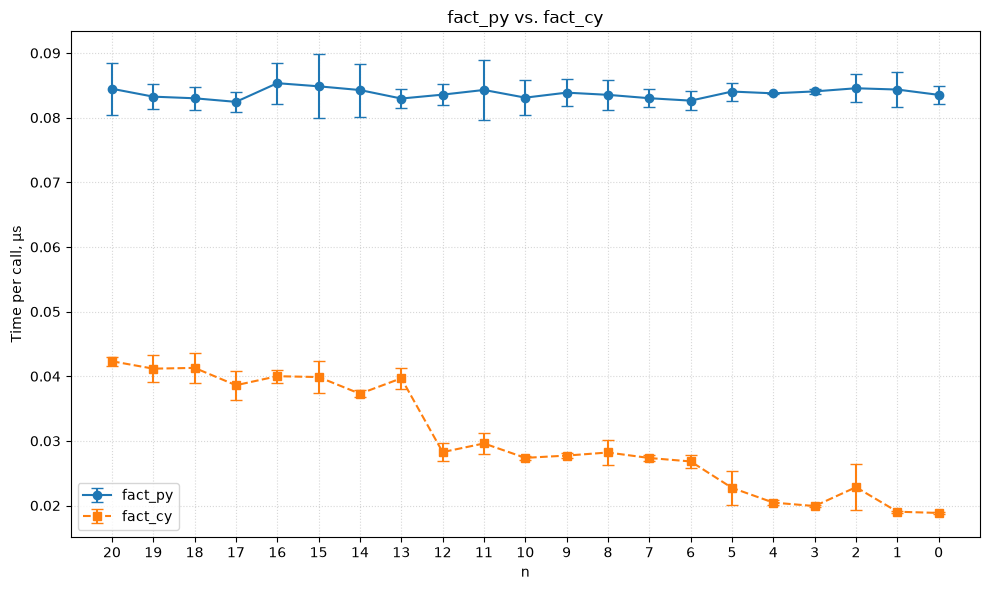

In [13]:
import functools
import timeit
import statistics
from collections.abc import Iterable

import matplotlib.pyplot as plt


def measure(f: Callable, *, number: int = 1000, repeat: int = 10) -> tuple[float, float]:
    res = timeit.repeat(f, number=number, repeat=repeat)
    mean = statistics.mean(res) / number * 1e6
    std = statistics.stdev(res) / number * 1e6
    return (mean, std)  # in microseconds


def plot_factorials(nums: Iterable[int]) -> None:
    nums = list(nums)

    results_cy: list[tuple[float, float]] = [
        measure(functools.partial(factorial_cy, n))
        for n in nums
    ]
    means_cy = [r[0] for r in results_cy]
    stds_cy = [r[1] for r in results_cy]

    results_py: list[tuple[float, float]] = [
        measure(functools.partial(factorial_py, n))
        for n in nums
    ]
    means_py = [r[0] for r in results_py]
    stds_py = [r[1] for r in results_py]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.errorbar(nums, means_py, yerr=stds_py, fmt='o-', label='fact_py', capsize=4, linewidth=1.5, markersize=6)
    ax.errorbar(nums, means_cy, yerr=stds_cy, fmt='s--', label='fact_cy', capsize=4, linewidth=1.5, markersize=6)
    
    ax.set_xlabel('n')
    ax.set_ylabel('Time per call, µs')
    ax.set_title('fact_py vs. fact_cy')
    ax.set_xticks(nums)
    ax.invert_xaxis()
    
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()


nums = list(range(20, -1, -1))
plot_factorials(nums)

И снова Сайтон обогнал Пайтон, но не нужно спешить с радостью и впихивать Сайтон куда угодно и без мыла. Важно отметить, что при последовательном исполнении ячеек, кэш динамически запрограммированной функции уже был наполнен требуемыми значениями и так задумывалось. Картинка выше показывает несоизмеримые замеры: честный насчёт значений в сайтонячей функции и выборка из кэша в питонячей.

Но что если прогнать другой ряд чисел?

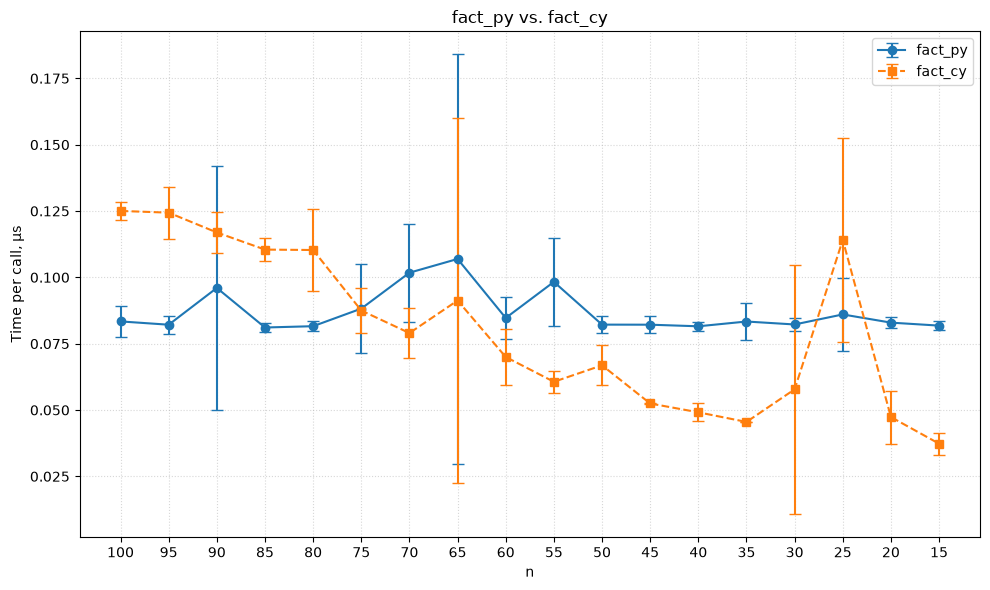

In [14]:
nums = list(range(100, 10, -5))
plot_factorials(nums)

Ооо, уже не так впечатляюще, пайтоновская функция вполне хорошо (порой очень хорошо) справляется со своей работой, да у неё ещё и нет ограничений (сишных) сайтоновской функции (а ведь там ещё и сломанная проверка на переполнение). Не вижу веских слагаемых в пользу сайтонической функции и это хорошо, а ещё "добрым молодцам урок": Rust (и всякое "X лучше Y") хорош, но не нужно ломиться со спотыками и перекладывать кодовую основу на "ржавые" рельсы.

### Посленаписанное (post scriptum)

- Знание алгосов и "матеши" стоит того!
- Зачастую достаточно "обычных" решений пока не возникло необходимости или удачной и дешёвой возможности в улучшениях.
- Разумное сомнение хорошо иметь бдительной привычкой, иначе эта заметка приводила бы к неявному и **неверному** выводу, что *Cython код быстрее Python кода*.
- Cython - это допзависимость, а значит она может внести своё влияние и риски: проект может загнуться, в нём могут долгое время не исправляться ошибки, возможно и критические, когда "улучшенный" код протекает по памяти просто из-за ошибок в Cython.

До сих пор везде был "отсутствующий косяк": ячейки запускались без спасительных флагов компиляции `-Wall -Werror -Wextra` - этих трёх парней нужно звать на всякую компиляцию (вам же лучше будет).

In [15]:
%%cython -c=-Wall -c=-Werror -c=-Wextra

# cdef = Cython specific function inacessible in Python environment
cdef void hello_cython():
    print("Hello, Cython!")

hello_cython()

Hello, Cython!


Здесь используется `cdef` функция - сугубо сайтоновская функция, которая не видна из Python, в чём можно убедиться:

In [16]:
# %%cython -c=-Wall -c=-Werror -c=-Wextra

hello_cython()

NameError: name 'hello_cython' is not defined

Также есть `cpdef` функции - они видны как для Пайтона, так и для Сайтона: своеродная помесь (гибрид) двух миров - пока довольствуюсь этим поверхностным описанием. В прошлый раз одним из примеров послужила сумма арифметической прогрессии, в этот раз можно посчитать [суммой геометрической прогрессии](https://ru.wikipedia.org/wiki/%D0%93%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D0%BF%D1%80%D0%BE%D0%B3%D1%80%D0%B5%D1%81%D1%81%D0%B8%D1%8F).

In [17]:
%%cython -c=-Wall -c=-Werror -c=-Wextra

cpdef long double sum_geom(int n, double a, double q):
    if n <= 0:
        return 0
    if q == 1:
        return a * n
    cdef double numerator = a * (1.0 - q ** n)
    cdef double denominator = 1.0 - q
    return numerator / denominator

In [18]:
from math import isclose

a, q = 2, 0.5

assert isclose(sum_geom(0, a, q), 0)
assert isclose(sum_geom(2, a, 1), 4)
assert isclose(sum_geom(3, a, q), 3.5)

Чуть подробнее за эти разновиды функций написано [здесь](https://cython.readthedocs.io/en/latest/src/userguide/language_basics.html#python-functions-vs-c-functions), а пока хватит почеркушек.